# FOVs as vectors in rule space  -  positive and negative rules

The same as the positive notebook, with the rules where cell types avoid each other kept as well.


In [1]:
import os
import sys

sys.path.append(os.path.abspath('../..'))   # project root
sys.path.append(os.path.abspath('..'))            # shared helpers, one level up

import rule_space_helper as rs
# Which mining run: data_helper.RESULT_CSV_PATH, shared by every notebook.
# To read a different one, pass its path to dh.load_results / rs.load below.


In [2]:
# --- Settings for this run. Everything else is left at the helper's default. ---
rs.METRIC            = 'Lift'
rs.POSITIVE_ONLY     = False
rs.RULE_MAX_ITEMS    = 2
rs.NO_SELF           = False
rs.MIN_FOV_THRESHOLD = 0.1
rs.SCORE_COL         = 'Pathological score'

data = rs.load()


Dropped 21 FOVs: Control_S
Loaded 598093 cells; FOVs: 267, biopsies: 73, patients: 71
Read results_CN_pairwise.csv + results_CN_complex.csv
Loaded 798432 rules.
Kept 162469 rules at FDR <= 0.05.
Kept 27105 rules that add information.
Kept 26759 rules naming no Unidentified.
Kept 26759 rules (max_items=4, kind=None).


## 1. All FOVs

Every stage and both organs. The two scatters are the same PCA coloured twice, so they can be compared directly.


both organs, all stages: 262 FOVs x 60 columns  |  PC1 12.3%  PC2 7.1%
  pair: GVHD_15_FOV_3 + GVHD_16_FOV_3  (0.52 apart, nothing else within 1.14)


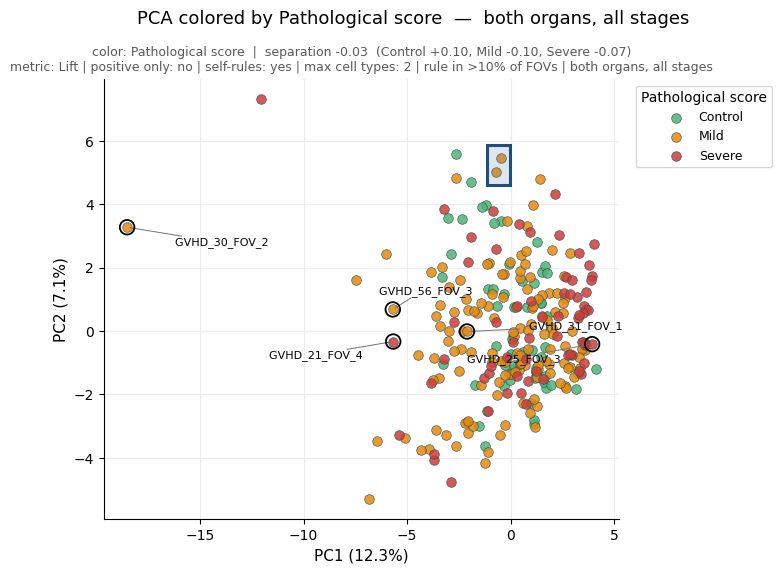

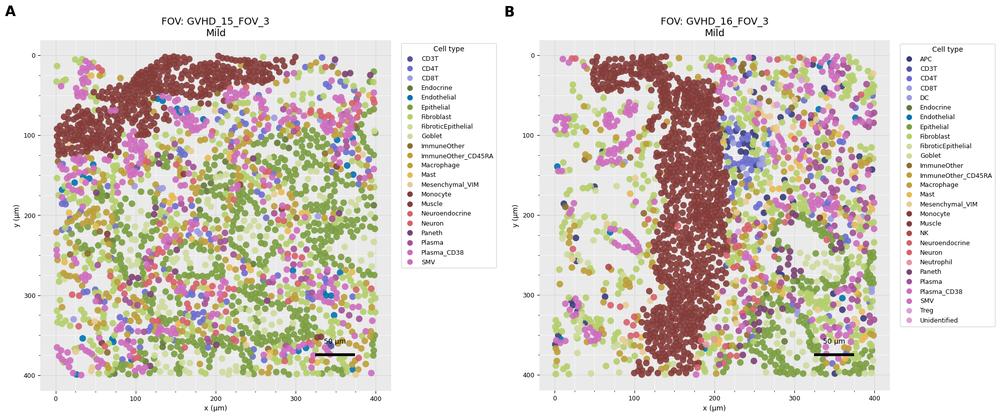

  pair: GVHD_15_FOV_3 + GVHD_16_FOV_3  (0.52 apart, nothing else within 1.14)
saved summary_downloads\posneg_all_pca_organ.pdf


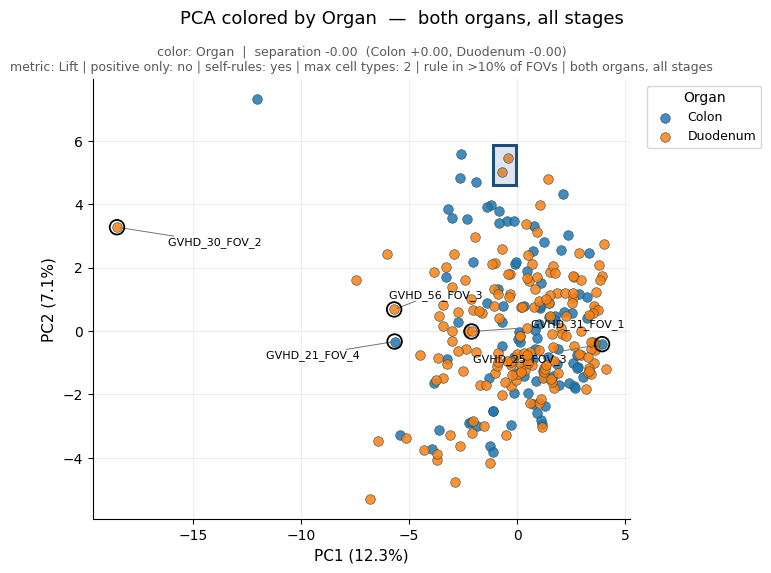

saved summary_downloads\posneg_all_pair_fovs.pdf


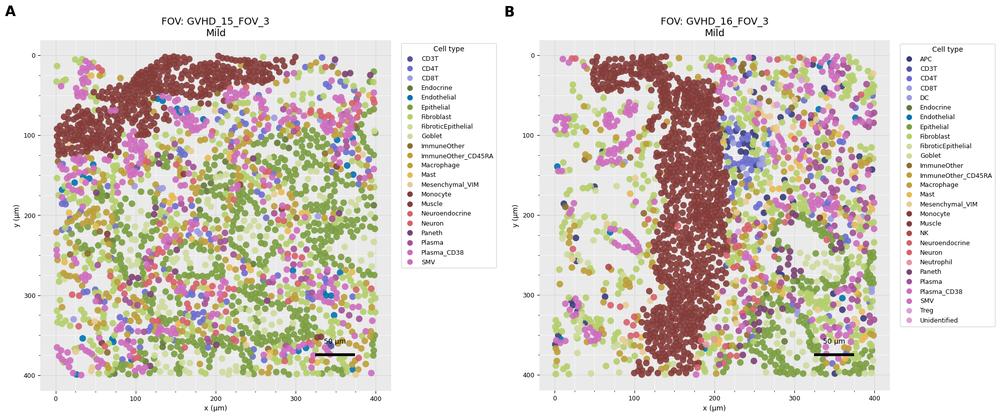

In [3]:
all_fovs = rs.run(data,
                   prefix='posneg_all', diagnostics=False)

rs.pair(data, all_fovs);   # drawn to look at; the write-up uses the organ one          # where the FOVs fall, and the closest pair
rs.pair(data, all_fovs, color_by="Organ", save=True);          # where the FOVs fall, and the closest pair


both organs, all stages: 263 FOVs x 274 columns  |  PC1 3.8%  PC2 3.2%
  pair: Control_02_FOV_2 + Control_Colon_03_FOV_5  (0.75 apart, nothing else within 1.35)
saved summary_downloads\posneg_all_pca_organ.pdf


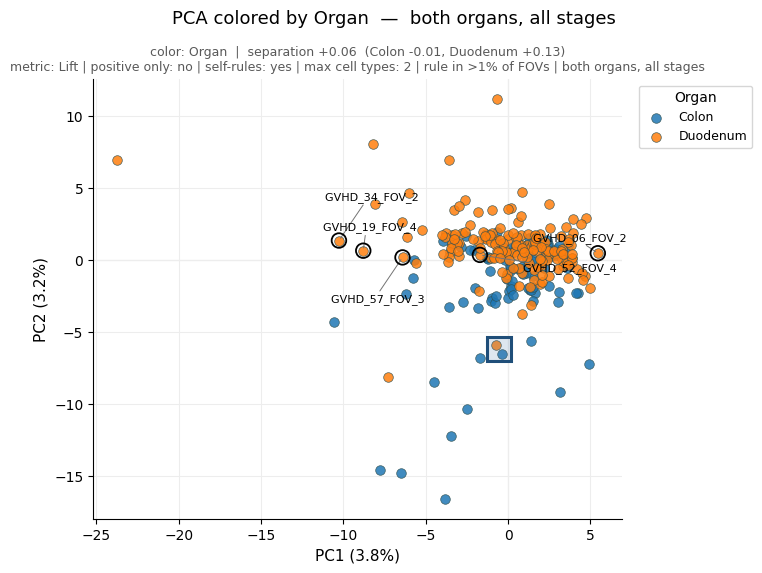

saved summary_downloads\posneg_all_pair_fovs.pdf


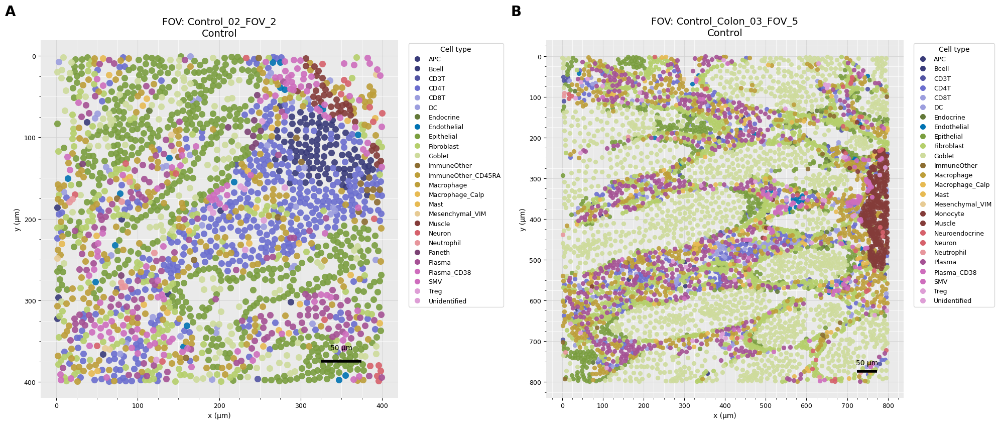

  GVHD_34_FOV_2              PC1 low | -10.27 (PC2 1.36) | Duodenum (Mild)
  GVHD_19_FOV_4              PC1 mid-low | -8.79 (PC2 0.65) | Duodenum (Mild)
  GVHD_57_FOV_3              PC1 middle | -6.41 (PC2 0.18) | Duodenum (Severe)
  GVHD_52_FOV_4              PC1 mid-high | -1.71 (PC2 0.36) | Duodenum (Mild)
  GVHD_06_FOV_2              PC1 high | 5.45 (PC2 0.48) | Duodenum (Severe)
saved summary_downloads\posneg_all_fovs_pc1.pdf


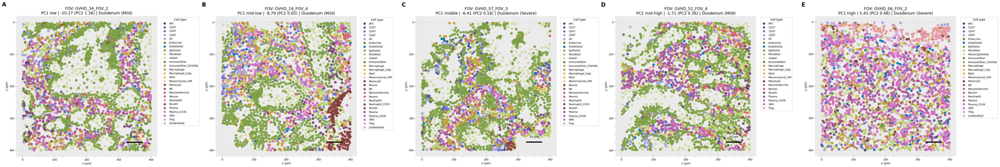

  GVHD_50_FOV_2              PC2 low | -16.58 (PC1 -3.80) | Colon (Mild)
  Control_Colon_03_FOV_5     PC2 mid-low | -6.51 (PC1 -0.35) | Colon (Control)
  GVHD_59_FOV_1              PC2 middle | -2.40 (PC1 0.33) | Colon (Mild)
  GVHD_31_FOV_3              PC2 mid-high | 4.73 (PC1 0.85) | Duodenum (Mild)
  GVHD_57_FOV_1              PC2 high | 11.17 (PC1 -0.69) | Duodenum (Severe)


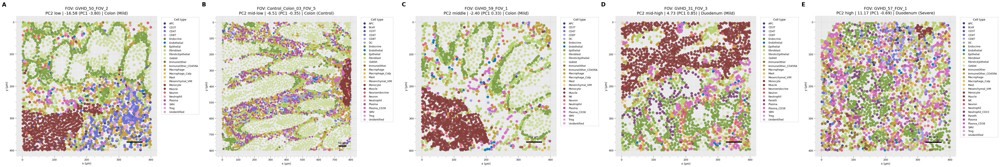

saved summary_downloads\posneg_all_loadings_pc1.pdf


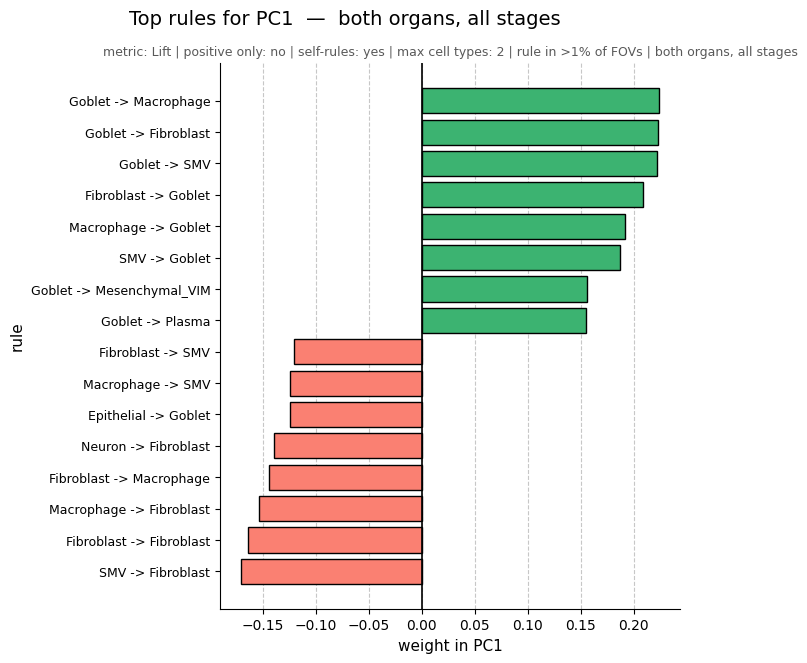

saved summary_downloads\posneg_all_loadings_pc2.pdf


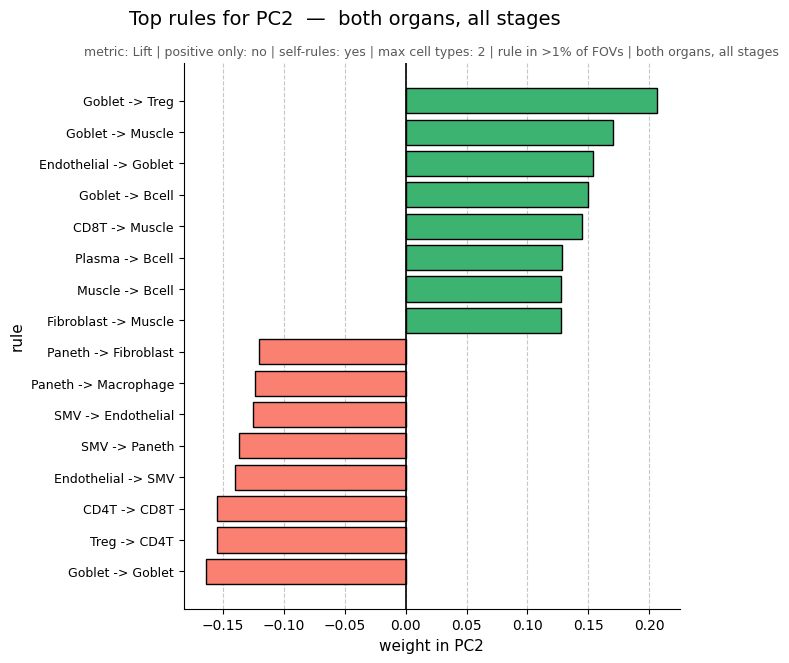

  71 patients with 2+ FOVs | 54 sit closer together than average | median 0.53
saved summary_downloads\posneg_all_patient_spread.pdf


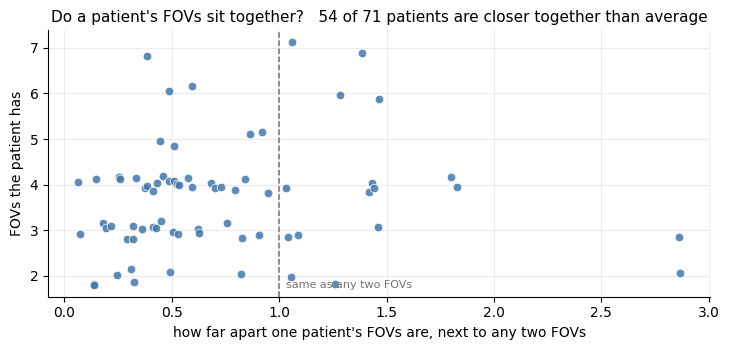

In [4]:
rs.MIN_FOV_THRESHOLD = 0.01
all_fovs = rs.run(data,
                   prefix='posneg_all', diagnostics=False)


rs.pair(data, all_fovs, color_by="Organ", save=True);          # where the FOVs fall, and the closest pair

rs.fov_panel(data, all_fovs, save=True);     # the ends of PC1, as real tissue
rs.fov_panel(data, all_fovs, component='PC2')
rs.loadings(all_fovs, save=True);          # the rules pulling on PC1 and PC2
rs.patient_spread(all_fovs, save=True);   # do a patient's FOVs sit together?
rs.MIN_FOV_THRESHOLD = 0.1


## 1.1. Colon, all stages

Every stage of one organ. The colourings below are the biopsy metadata - days after the
transplant, donor type, cortico response, survival - which need all the stages present to
be worth asking about.


Colon, all stages: 96 FOVs x 66 columns  |  PC1 12.8%  PC2 10.1%


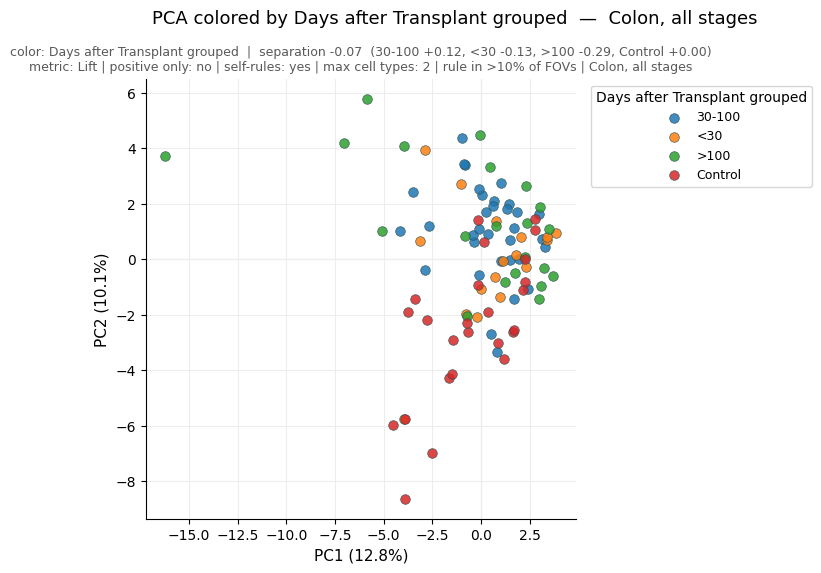

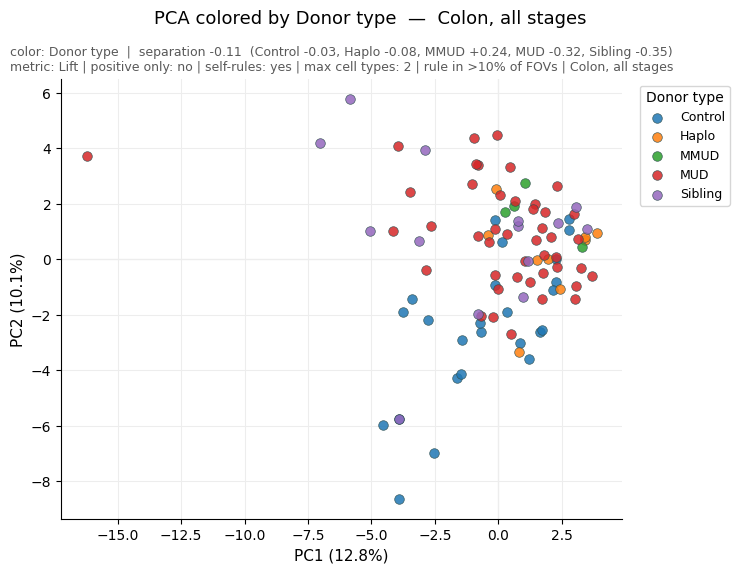

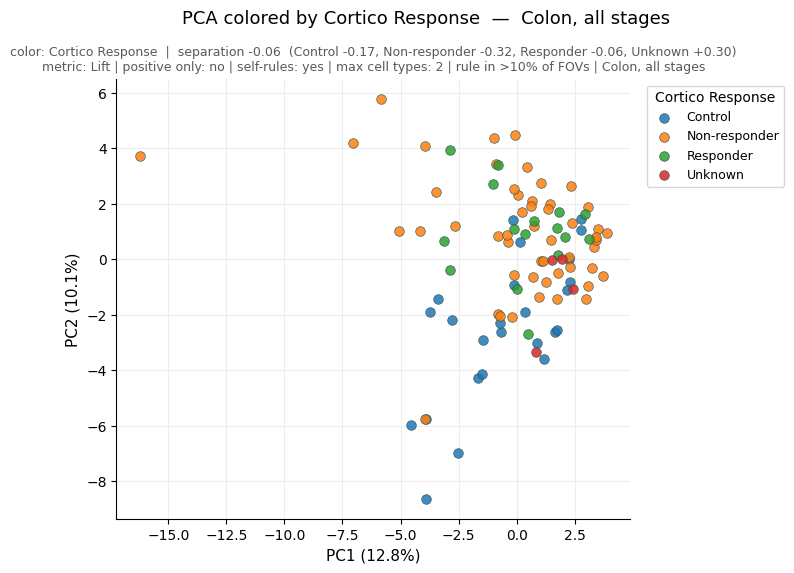

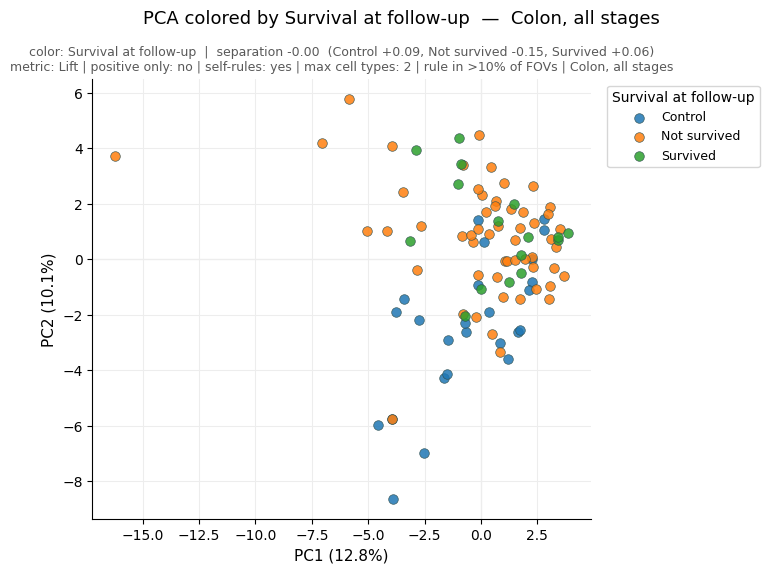

In [5]:
colon_all = rs.run(data,
                    organs=['Colon'], prefix='posneg_colon',
                    colors=rs.METADATA_COLORS, diagnostics=False)


## 1.2. Duodenum, all stages

Every stage of one organ. The colourings below are the biopsy metadata - days after the
transplant, donor type, cortico response, survival - which need all the stages present to
be worth asking about.


Duodenum, all stages: 167 FOVs x 70 columns  |  PC1 12.9%  PC2 7.0%


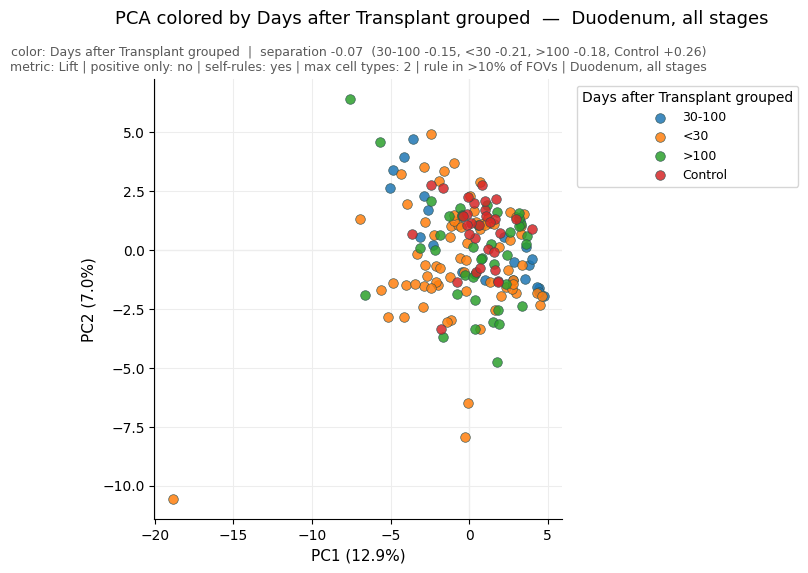

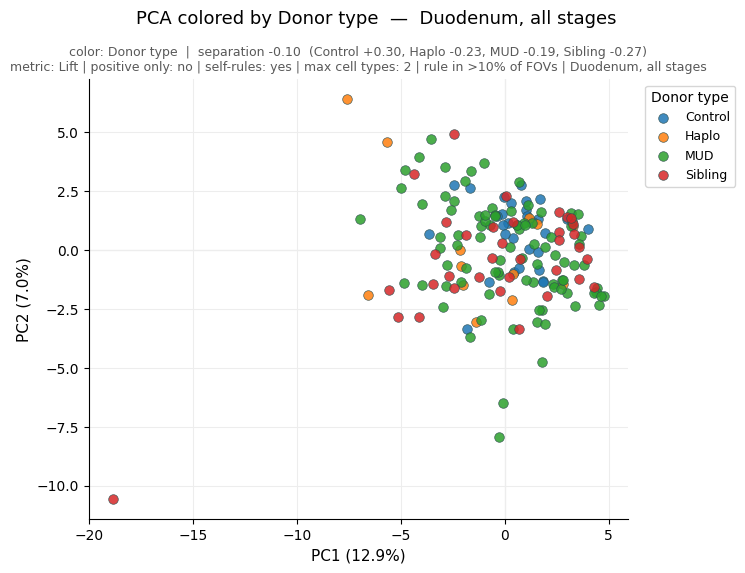

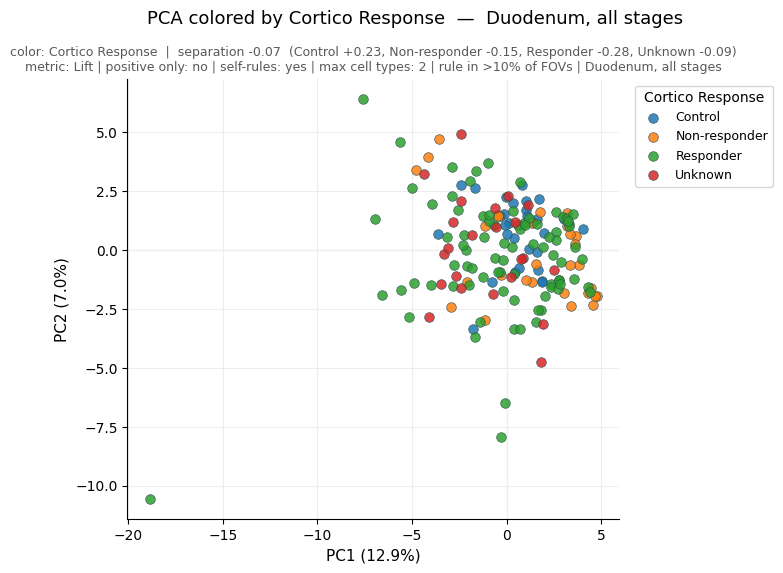

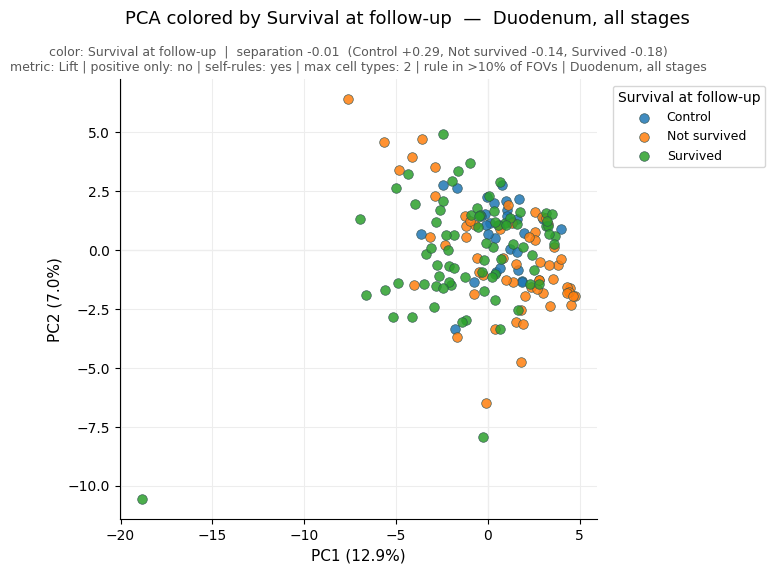

In [6]:
duodenum_all = rs.run(data,
                       organs=['Duodenum'], prefix='posneg_duodenum',
                       colors=rs.METADATA_COLORS, diagnostics=False)


## 1.3. Do the FOVs of one stage sit together?

The atlas describes the healthy gut as stereotypical across individuals and disease as
varied, so the Control FOVs are the ones expected to sit tightest here. This is the
same measure as the patient spread above, one level up: a stage instead of a patient.


  both organs, all stages: tightest is Severe at 0.93
saved summary_downloads\posneg_all_group_spread.pdf


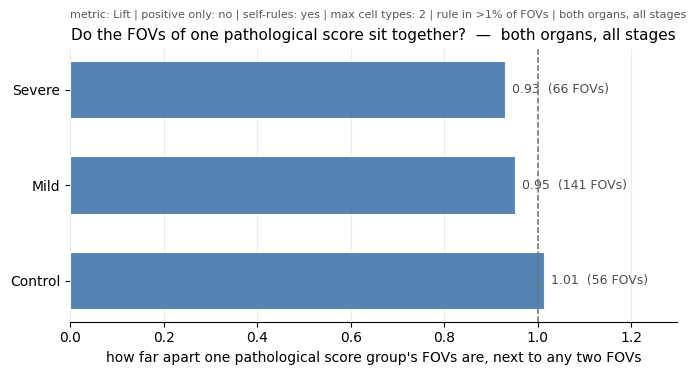

  Colon, all stages: tightest is Mild at 0.77
saved summary_downloads\posneg_colon_group_spread.pdf


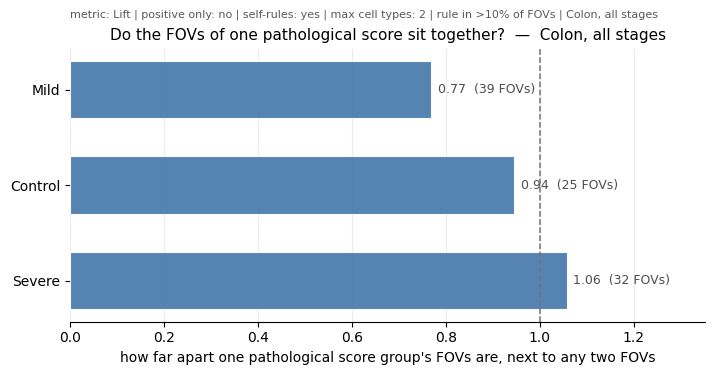

  Duodenum, all stages: tightest is Control at 0.59
saved summary_downloads\posneg_duodenum_group_spread.pdf


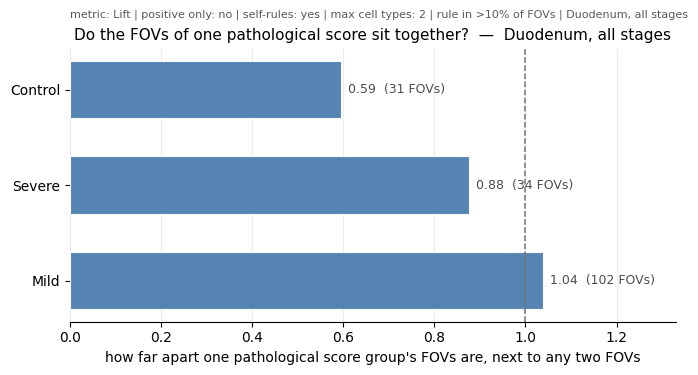

In [7]:
for scope in (all_fovs, colon_all, duodenum_all):
    rs.group_spread(scope, save=True);   # below 1.0 = that stage's FOVs are alike


## 2. Colon, Control vs Severe

The two extreme stages inside one organ, so neither organ nor the middle stages can explain a split.


Colon, Control vs Severe: 57 FOVs x 78 columns  |  PC1 12.6%  PC2 12.0%
  pair: GVHD_01_FOV_3_R + GVHD_41_FOV_3  (0.50 apart, nothing else within 0.88)
saved summary_downloads\posneg_cs_colon_pca_pathological_score.pdf


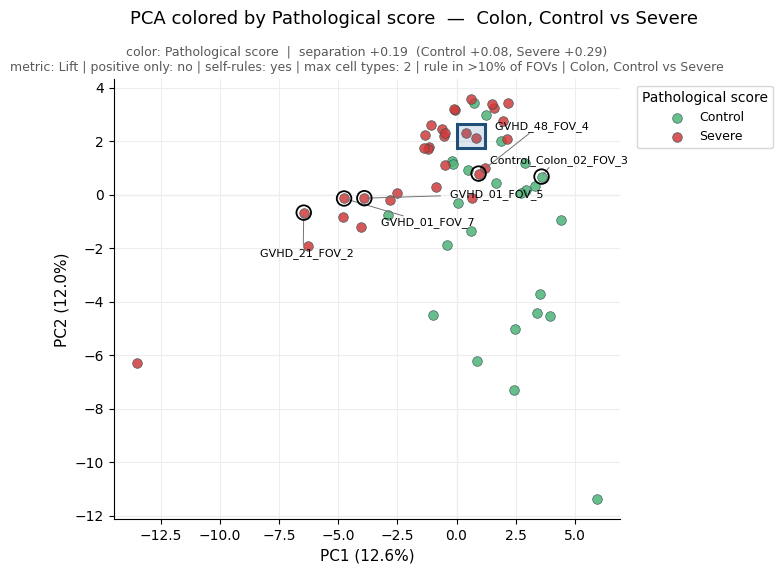

saved summary_downloads\posneg_cs_colon_pair_fovs.pdf


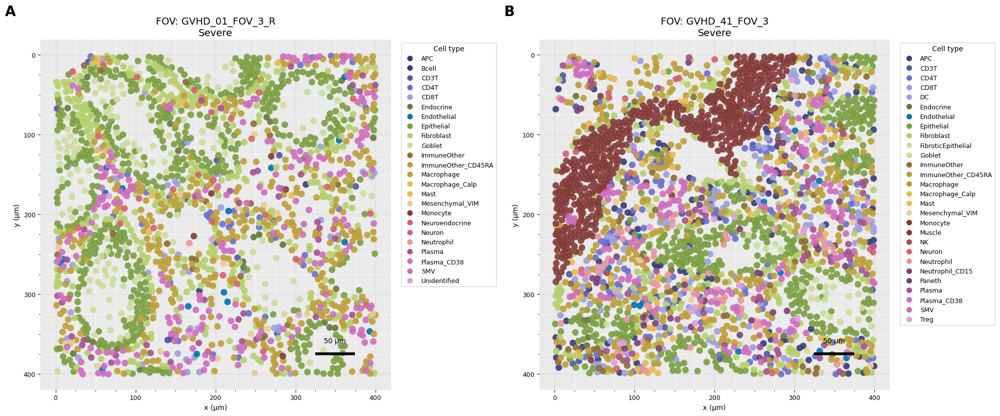

  GVHD_21_FOV_2              PC1 low | -6.45 (PC2 -0.68) | Colon (Severe)
  GVHD_01_FOV_7              PC1 mid-low | -4.75 (PC2 -0.15) | Colon (Severe)
  GVHD_01_FOV_5              PC1 middle | -3.89 (PC2 -0.14) | Colon (Severe)
  GVHD_48_FOV_4              PC1 mid-high | 0.93 (PC2 0.78) | Colon (Severe)
  Control_Colon_02_FOV_3     PC1 high | 3.59 (PC2 0.67) | Colon (Control)
saved summary_downloads\posneg_cs_colon_fovs_pc1.pdf


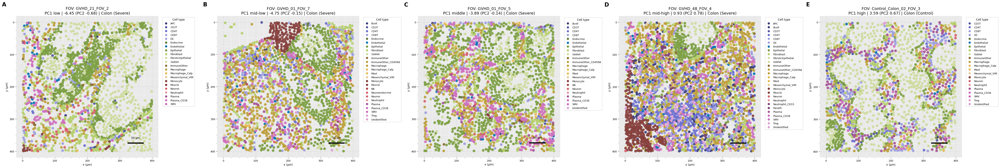

  Control_Colon_04_FOV_6     PC2 low | -6.21 (PC1 0.88) | Colon (Control)
  Control_Colon_04_FOV_5     PC2 mid-low | -7.32 (PC1 2.43) | Colon (Control)
  Control_Colon_04_FOV_4     PC2 middle | -1.36 (PC1 0.59) | Colon (Control)
  GVHD_41_FOV_4              PC2 mid-high | -0.13 (PC1 0.63) | Colon (Severe)
  GVHD_32_FOV_1              PC2 high | 3.56 (PC1 0.63) | Colon (Severe)


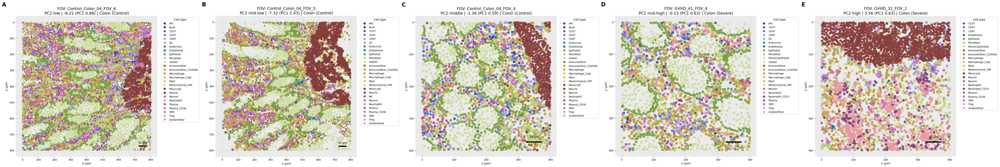

saved summary_downloads\posneg_cs_colon_loadings_pc1.pdf


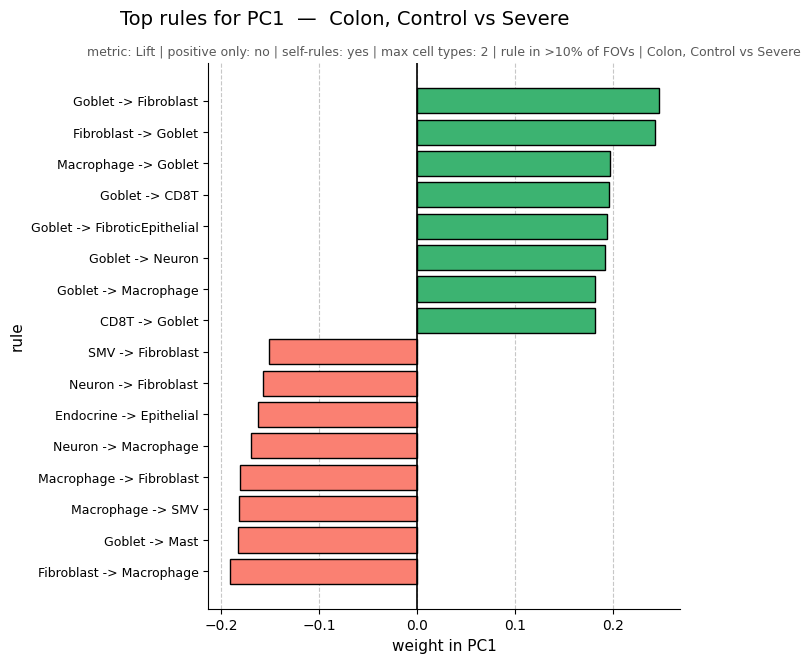

saved summary_downloads\posneg_cs_colon_loadings_pc2.pdf


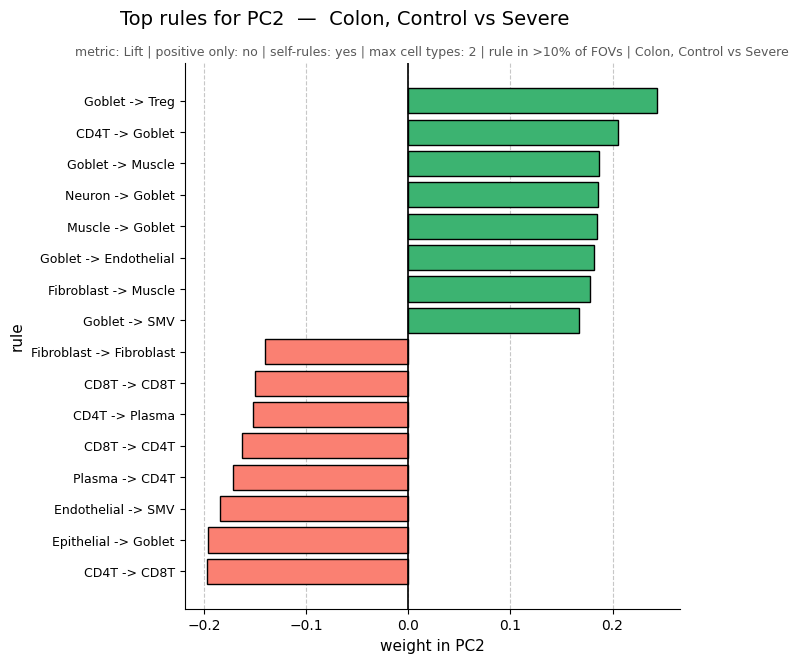

In [8]:
control_severe_colon = rs.run(data,
                               stages=['Control', 'Severe'], organs=['Colon'],
                               prefix='posneg_cs_colon', diagnostics=False)

rs.pair(data, control_severe_colon, save=True);          # where the FOVs fall, and the closest pair

rs.fov_panel(data, control_severe_colon, save=True);     # the ends of PC1, as real tissue
rs.fov_panel(data, control_severe_colon, component='PC2')
rs.loadings(control_severe_colon, save=True);          # the rules pulling on PC1 and PC2

## 3. Duodenum, Control vs Severe

The same two stages in the other organ.


Duodenum, Control vs Severe: 65 FOVs x 51 columns  |  PC1 19.3%  PC2 10.6%
saved summary_downloads\posneg_cs_duodenum_pca_plain.pdf


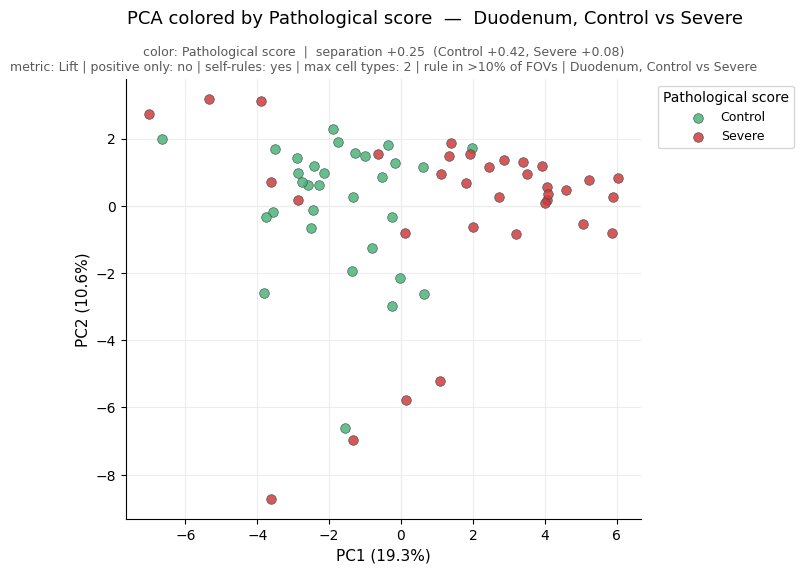

  pair: Control_01_FOV_1 + GVHD_14_FOV_2  (0.42 apart, nothing else within 1.91)
saved summary_downloads\posneg_cs_duodenum_pca_pathological_score.pdf


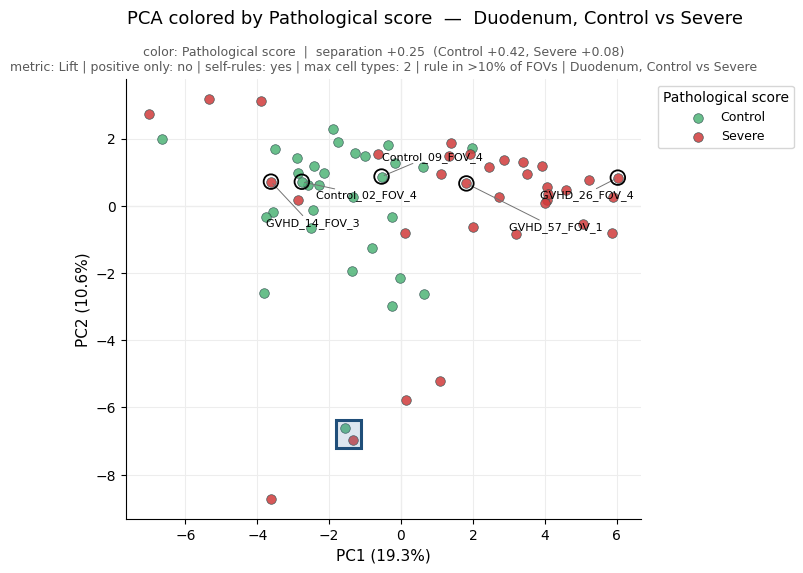

saved summary_downloads\posneg_cs_duodenum_pair_fovs.pdf


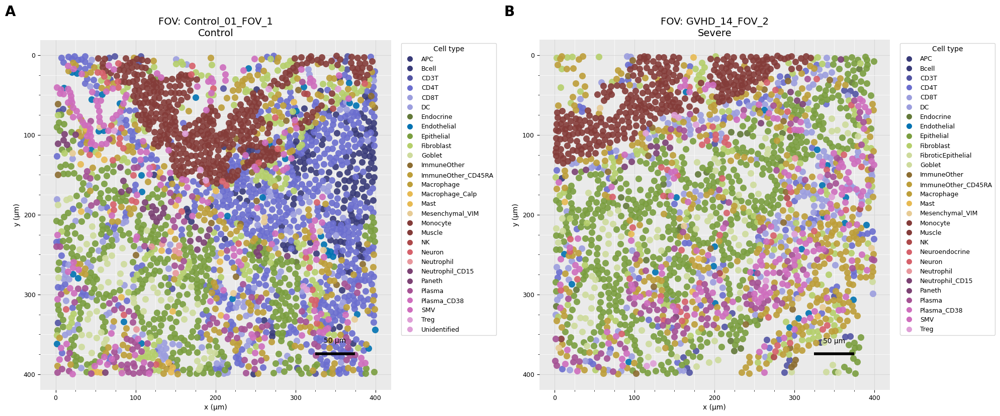

  GVHD_14_FOV_3              PC1 low | -3.62 (PC2 0.72) | Duodenum (Severe)
  Control_02_FOV_4           PC1 mid-low | -2.76 (PC2 0.71) | Duodenum (Control)
  Control_09_FOV_4           PC1 middle | -0.54 (PC2 0.87) | Duodenum (Control)
  GVHD_57_FOV_1              PC1 mid-high | 1.82 (PC2 0.66) | Duodenum (Severe)
  GVHD_26_FOV_4              PC1 high | 6.03 (PC2 0.84) | Duodenum (Severe)
saved summary_downloads\posneg_cs_duodenum_fovs_pc1.pdf


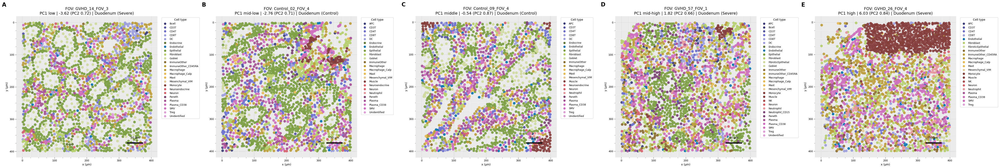

  GVHD_14_FOV_2              PC2 low | -6.98 (PC1 -1.34) | Duodenum (Severe)
  GVHD_14_FOV_1              PC2 mid-low | -5.79 (PC1 0.15) | Duodenum (Severe)
  Control_08_FOV_1           PC2 middle | -2.99 (PC1 -0.26) | Duodenum (Control)
  Control_09_FOV_3           PC2 mid-high | -0.33 (PC1 -0.24) | Duodenum (Control)
  Control_02_FOV_3           PC2 high | 1.81 (PC1 -0.35) | Duodenum (Control)


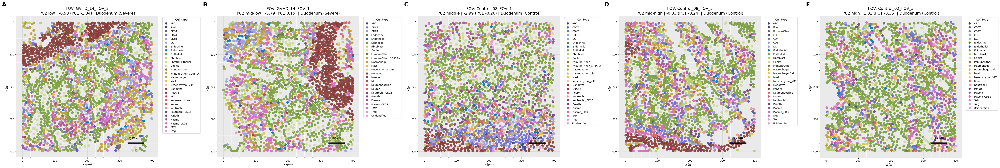

saved summary_downloads\posneg_cs_duodenum_loadings_pc1.pdf


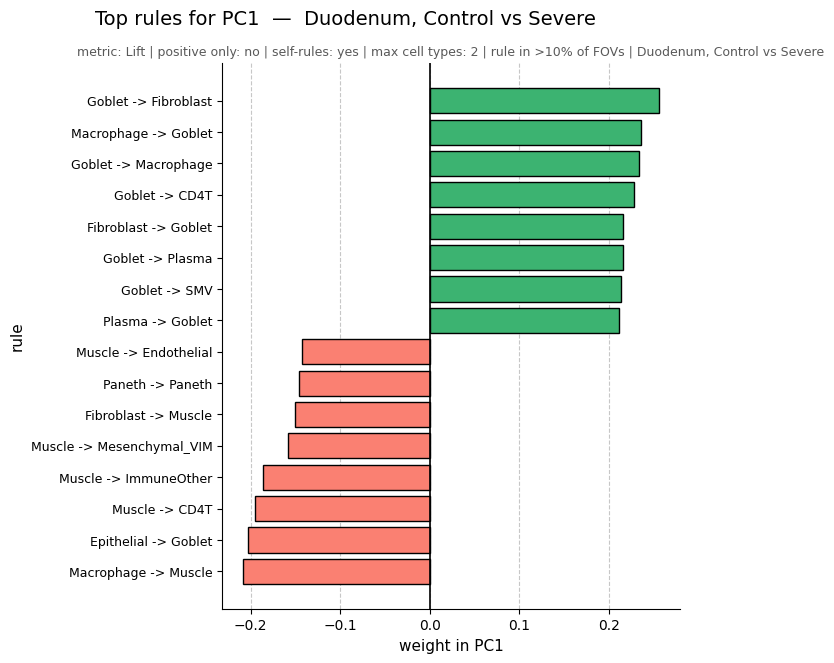

saved summary_downloads\posneg_cs_duodenum_loadings_pc2.pdf


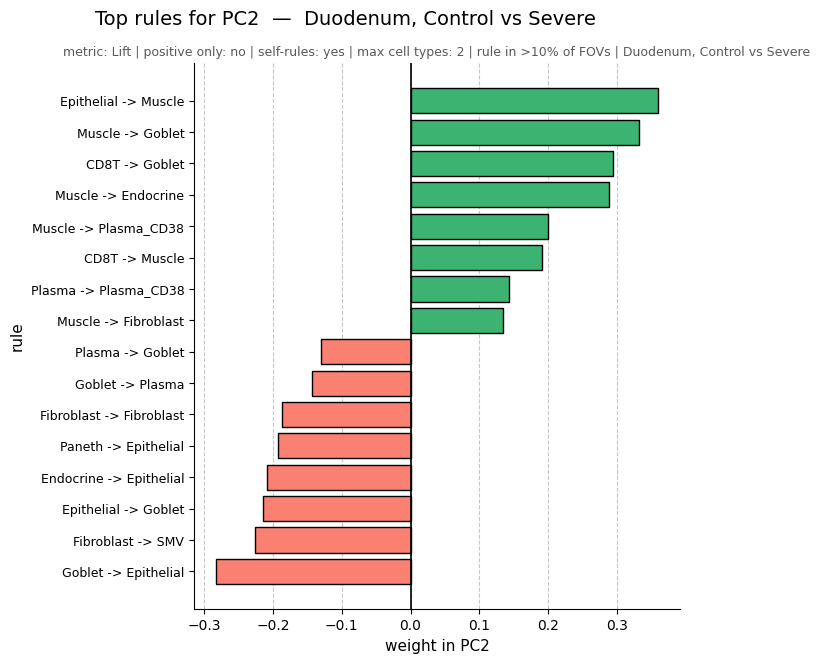

In [20]:
control_severe_duodenum = rs.run(data,
                                  stages=['Control', 'Severe'], organs=['Duodenum'],
                                  prefix='posneg_cs_duodenum', diagnostics=False)

rs.rsv.plot_pca_scatter(control_severe_duodenum.coords, control_severe_duodenum.variance,
                          color_by=rs.SCORE_COL, scope=control_severe_duodenum.label,
                          subtitle=rs._settings(control_severe_duodenum, rs.SCORE_COL),
                          save=rs.figure_name(f"{control_severe_duodenum.prefix}_pca_plain", True, pca=True));

rs.pair(data, control_severe_duodenum, save=True);          # where the FOVs fall, and the closest pair

rs.fov_panel(data, control_severe_duodenum, save=True);     # the ends of PC1, as real tissue
rs.fov_panel(data, control_severe_duodenum, component='PC2')
rs.loadings(control_severe_duodenum, save=True);          # the rules pulling on PC1 and PC2

## 3.1. The same two stages, without the FOVs sitting far out

Most of these FOVs sit in one dense clump with a few far away from it, and those few
set the axes for everyone else. Dropping them and fitting the PCA **again** - not
re-drawing the old one - asks whether the clump has a shape of its own.

Duodenum, Control vs Severe: 1 of 65 FOVs sit more than 3x the usual 2.84 out from the middle
  GVHD_14_FOV_5              3.5x
Duodenum, Control vs Severe: 64 FOVs x 48 columns  |  PC1 20.3%  PC2 9.4%
  pair: Control_02_FOV_1 + Control_07_FOV_3  (0.28 apart, nothing else within 0.61)
saved summary_downloads\posneg_cs_duodenum_trimmed_pca_pathological_score.pdf


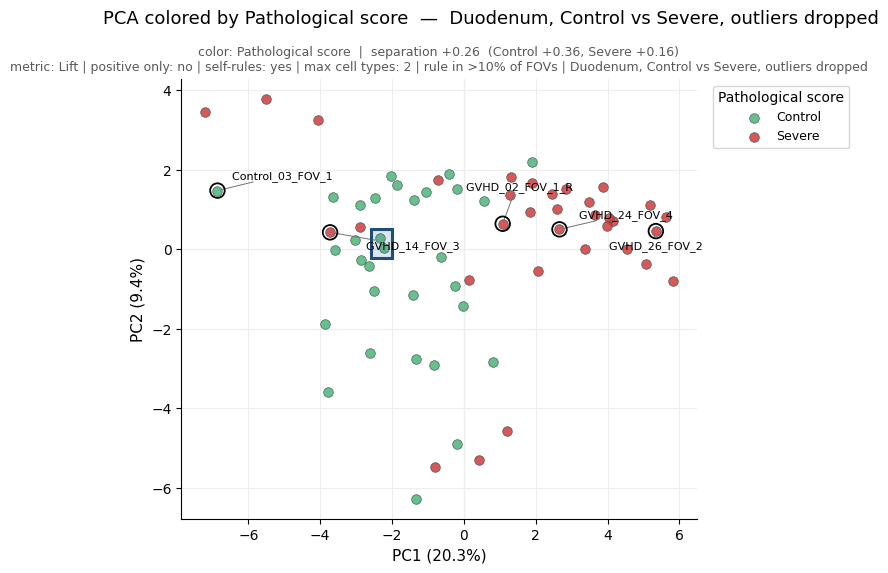

saved summary_downloads\posneg_cs_duodenum_trimmed_pair_fovs.pdf


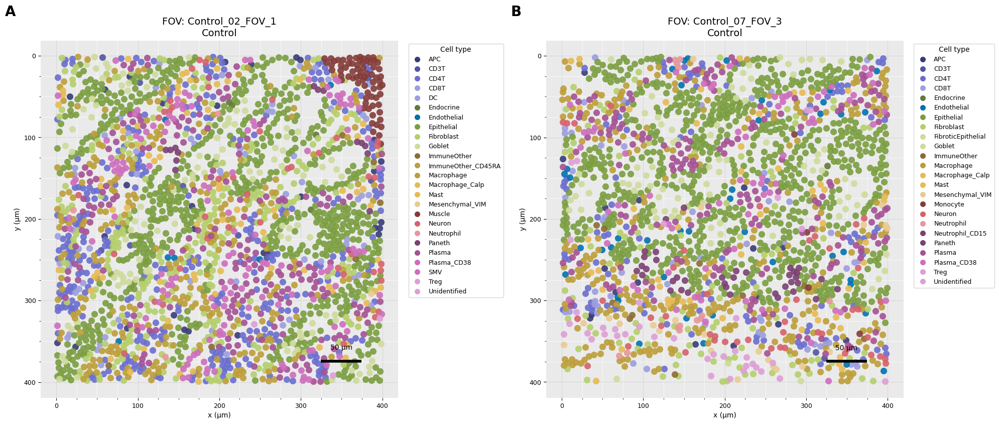

  Control_03_FOV_1           PC1 low | -6.86 (PC2 1.48) | Duodenum (Control)
  GVHD_14_FOV_3              PC1 mid-low | -3.72 (PC2 0.43) | Duodenum (Severe)
  GVHD_02_FOV_1_R            PC1 middle | 1.08 (PC2 0.65) | Duodenum (Severe)
  GVHD_24_FOV_4              PC1 mid-high | 2.66 (PC2 0.50) | Duodenum (Severe)
  GVHD_26_FOV_2              PC1 high | 5.34 (PC2 0.46) | Duodenum (Severe)
saved summary_downloads\posneg_cs_duodenum_trimmed_fovs_pc1.pdf


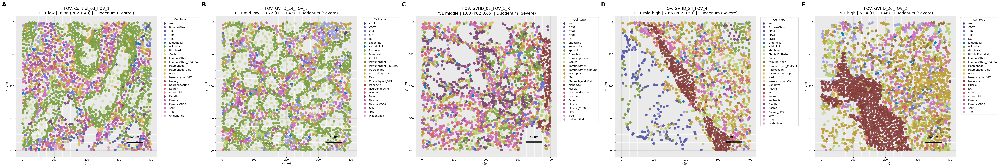

  GVHD_14_FOV_2              PC2 low | -5.48 (PC1 -0.81) | Duodenum (Severe)
  Control_08_FOV_1           PC2 mid-low | -4.88 (PC1 -0.18) | Duodenum (Control)
  Control_01_FOV_2           PC2 middle | -1.42 (PC1 -0.03) | Duodenum (Control)
  Control_06_FOV_2           PC2 mid-high | 1.52 (PC1 -0.20) | Duodenum (Control)
  Control_02_FOV_3           PC2 high | 1.90 (PC1 -0.41) | Duodenum (Control)


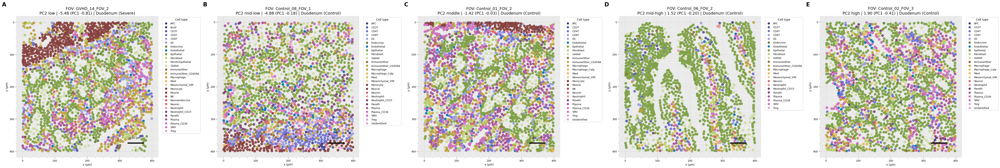

saved summary_downloads\posneg_cs_duodenum_trimmed_loadings_pc1.pdf


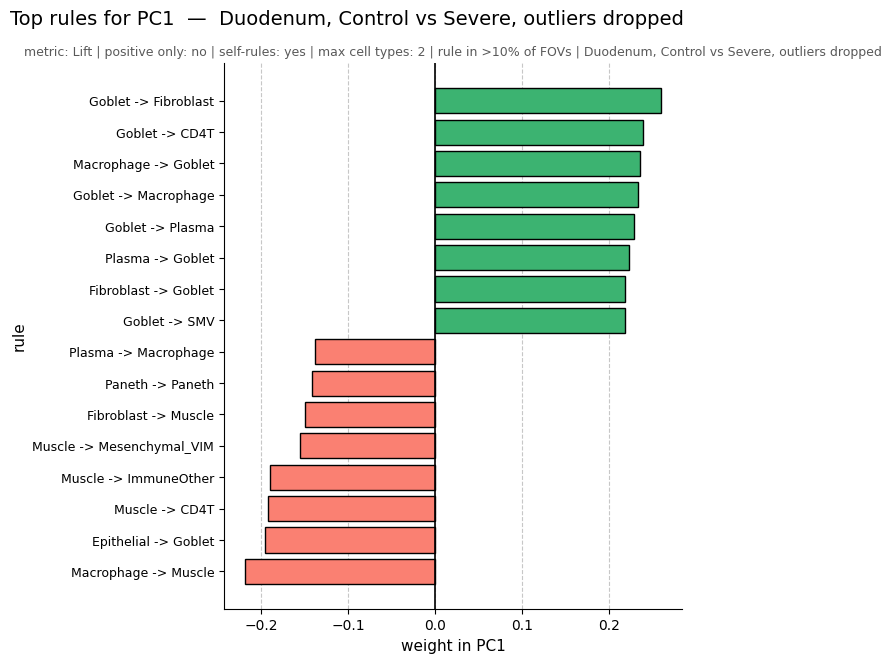

saved summary_downloads\posneg_cs_duodenum_trimmed_loadings_pc2.pdf


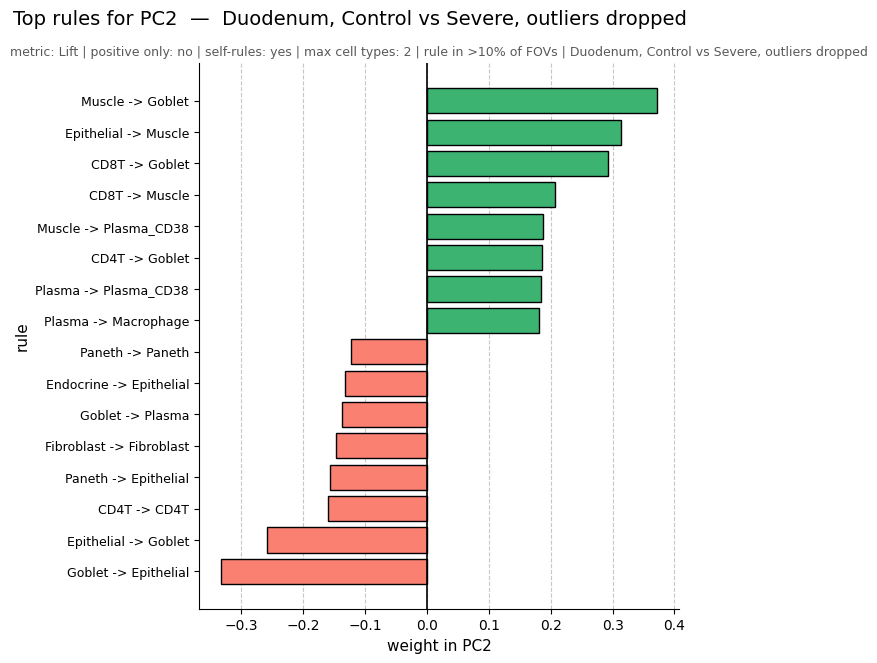

In [10]:
kept, dropped = rs.outliers(control_severe_duodenum, k=3)

trimmed_duodenum = rs.run(data,
                          stages=['Control', 'Severe'], organs=['Duodenum'],
                          fovs=kept, prefix='posneg_cs_duodenum_trimmed',
                          diagnostics=False)
trimmed_duodenum.built_from = 'outliers dropped'


rs.pair(data, trimmed_duodenum, save=True);          # where the FOVs fall now

rs.fov_panel(data, trimmed_duodenum, save=True);     # the ends of PC1, as real tissue
rs.fov_panel(data, trimmed_duodenum, component='PC2')
rs.loadings(trimmed_duodenum, save=True);          # the rules pulling on PC1 and PC2

## 4. Colon, Mild vs Severe

The two disease stages, without the healthy controls.


Colon, Mild vs Severe: 71 FOVs x 45 columns  |  PC1 18.9%  PC2 11.6%
  pair: GVHD_42_FOV_3 + GVHD_50_FOV_4  (0.34 apart, nothing else within 1.00)
saved summary_downloads\posneg_ms_colon_pca_pathological_score.pdf


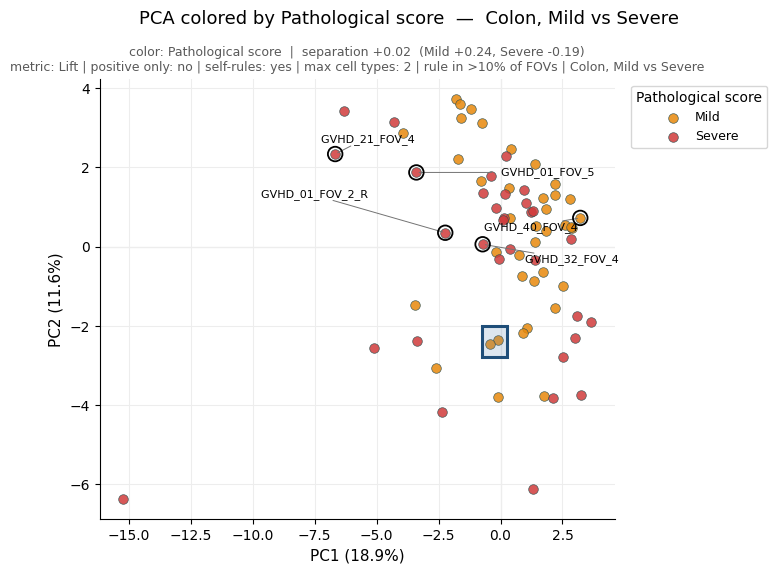

saved summary_downloads\posneg_ms_colon_pair_fovs.pdf


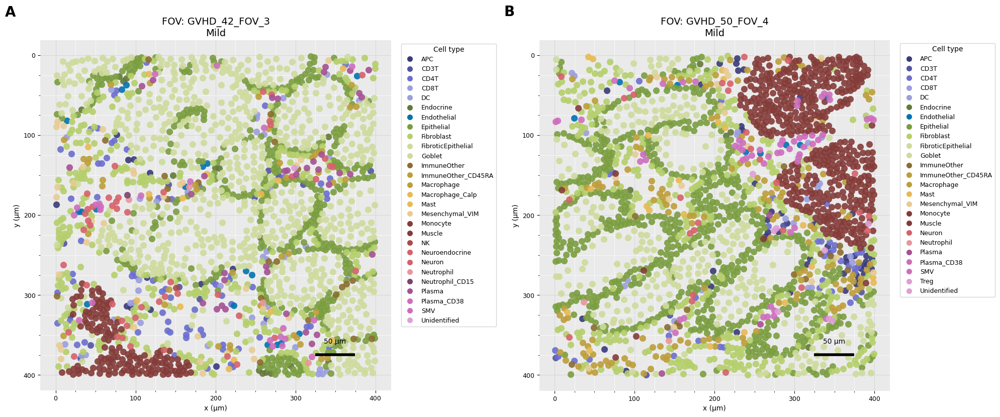

  GVHD_21_FOV_4              PC1 low | -6.67 (PC2 2.34) | Colon (Severe)
  GVHD_01_FOV_5              PC1 mid-low | -3.40 (PC2 1.87) | Colon (Severe)
  GVHD_01_FOV_2_R            PC1 middle | -2.23 (PC2 0.35) | Colon (Severe)
  GVHD_32_FOV_4              PC1 mid-high | -0.72 (PC2 0.06) | Colon (Severe)
  GVHD_40_FOV_4              PC1 high | 3.22 (PC2 0.72) | Colon (Mild)
saved summary_downloads\posneg_ms_colon_fovs_pc1.pdf


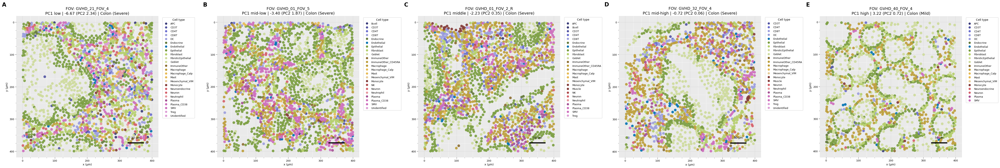

  GVHD_48_FOV_4              PC2 low | -6.12 (PC1 1.31) | Colon (Severe)
  GVHD_59_FOV_1              PC2 mid-low | -3.81 (PC1 -0.09) | Colon (Mild)
  GVHD_50_FOV_1              PC2 middle | -0.74 (PC1 0.88) | Colon (Mild)
  GVHD_23_FOV_1              PC2 mid-high | 1.47 (PC1 0.34) | Colon (Mild)
  GVHD_33_FOV_2              PC2 high | 2.46 (PC1 0.43) | Colon (Mild)


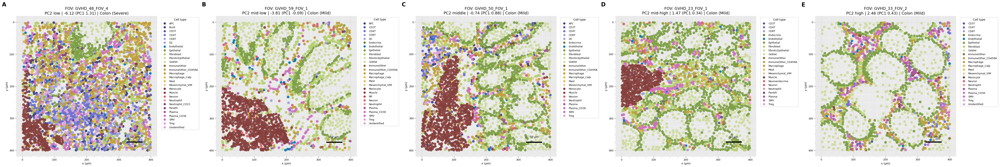

{'GVHD_48_FOV_4': 'PC2 low | -6.12 (PC1 1.31) | Colon (Severe)',
 'GVHD_59_FOV_1': 'PC2 mid-low | -3.81 (PC1 -0.09) | Colon (Mild)',
 'GVHD_50_FOV_1': 'PC2 middle | -0.74 (PC1 0.88) | Colon (Mild)',
 'GVHD_23_FOV_1': 'PC2 mid-high | 1.47 (PC1 0.34) | Colon (Mild)',
 'GVHD_33_FOV_2': 'PC2 high | 2.46 (PC1 0.43) | Colon (Mild)'}

In [11]:
mild_severe_colon = rs.run(data,
                            stages=['Mild', 'Severe'], organs=['Colon'],
                            prefix='posneg_ms_colon', diagnostics=False)

rs.pair(data, mild_severe_colon, save=True);          # where the FOVs fall, and the closest pair

rs.fov_panel(data, mild_severe_colon, save=True);     
rs.fov_panel(data, mild_severe_colon, component='PC2')


## 5. Duodenum, Mild vs Severe

The same two stages in the other organ.


Duodenum, Mild vs Severe: 136 FOVs x 70 columns  |  PC1 14.4%  PC2 7.1%
  pair: GVHD_14_FOV_2 + GVHD_18_FOV_3  (0.51 apart, nothing else within 1.06)
saved summary_downloads\posneg_ms_duodenum_pca_pathological_score.pdf


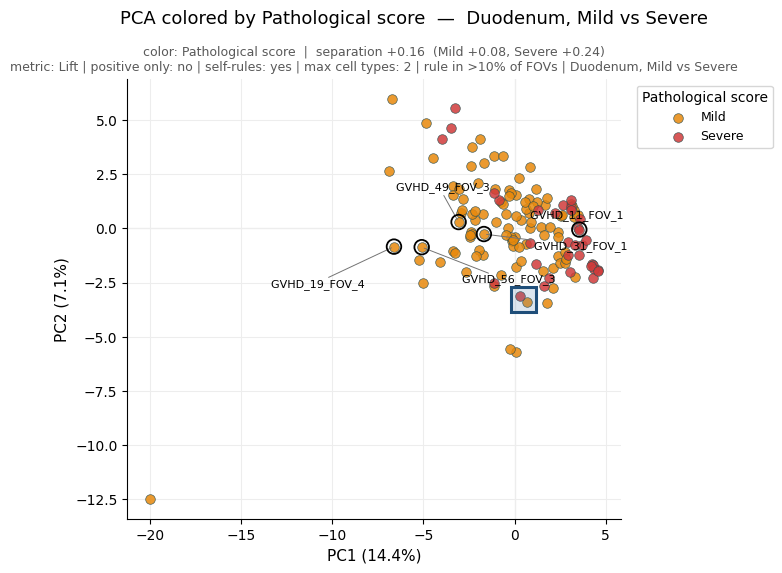

saved summary_downloads\posneg_ms_duodenum_pair_fovs.pdf


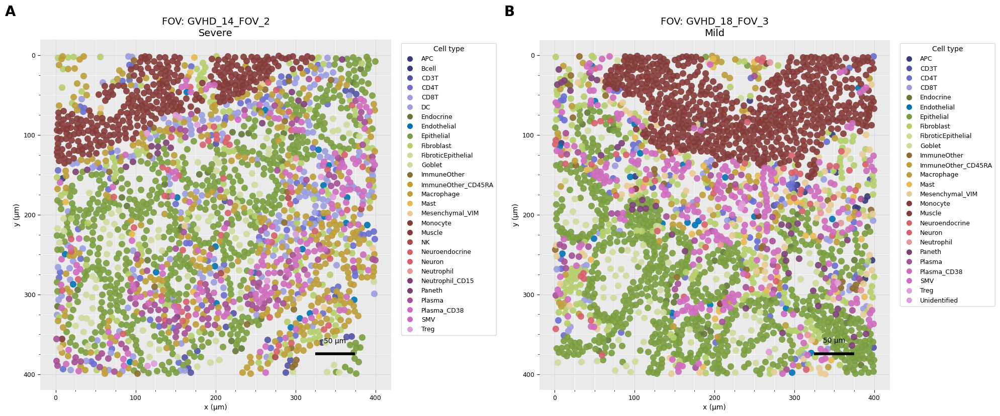

  GVHD_19_FOV_4              PC1 low | -6.62 (PC2 -0.84) | Duodenum (Mild)
  GVHD_56_FOV_3              PC1 mid-low | -5.09 (PC2 -0.86) | Duodenum (Mild)
  GVHD_49_FOV_3              PC1 middle | -3.07 (PC2 0.30) | Duodenum (Mild)
  GVHD_31_FOV_1              PC1 mid-high | -1.68 (PC2 -0.26) | Duodenum (Mild)
  GVHD_11_FOV_1              PC1 high | 3.55 (PC2 -0.05) | Duodenum (Severe)
saved summary_downloads\posneg_ms_duodenum_fovs_pc1.pdf


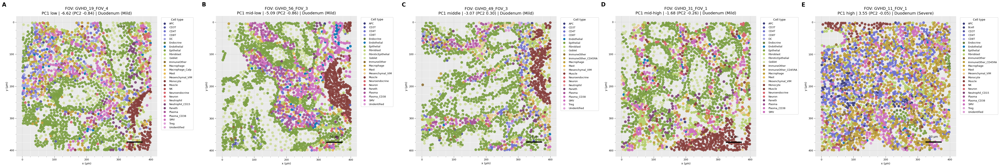

  GVHD_15_FOV_3              PC2 low | -5.68 (PC1 0.06) | Duodenum (Mild)
  GVHD_16_FOV_3              PC2 mid-low | -5.56 (PC1 -0.23) | Duodenum (Mild)
  GVHD_14_FOV_2              PC2 middle | -3.13 (PC1 0.28) | Duodenum (Severe)
  GVHD_47_FOV_1              PC2 mid-high | 1.54 (PC1 0.10) | Duodenum (Mild)
  GVHD_47_FOV_2              PC2 high | 3.36 (PC1 -0.65) | Duodenum (Mild)


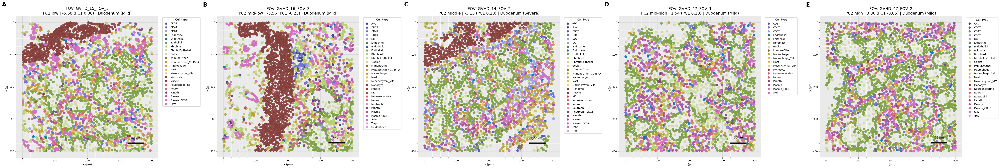

{'GVHD_15_FOV_3': 'PC2 low | -5.68 (PC1 0.06) | Duodenum (Mild)',
 'GVHD_16_FOV_3': 'PC2 mid-low | -5.56 (PC1 -0.23) | Duodenum (Mild)',
 'GVHD_14_FOV_2': 'PC2 middle | -3.13 (PC1 0.28) | Duodenum (Severe)',
 'GVHD_47_FOV_1': 'PC2 mid-high | 1.54 (PC1 0.10) | Duodenum (Mild)',
 'GVHD_47_FOV_2': 'PC2 high | 3.36 (PC1 -0.65) | Duodenum (Mild)'}

In [12]:
mild_severe_duodenum = rs.run(data,
                               stages=['Mild', 'Severe'], organs=['Duodenum'],
                               prefix='posneg_ms_duodenum', diagnostics=False)

rs.pair(data, mild_severe_duodenum, save=True);

rs.fov_panel(data, mild_severe_duodenum, save=True);     # the ends of PC1, as real tissue
rs.fov_panel(data, mild_severe_duodenum, component='PC2')

Colon, Control vs Mild vs Severe: 96 FOVs x 66 columns  |  PC1 12.8%  PC2 10.1%
  pair: Control_Colon_03_FOV_3 + GVHD_53_FOV_1  (0.30 apart, nothing else within 0.46)
saved summary_downloads\posneg_cm_severe_colon_pca_pathological_score.pdf


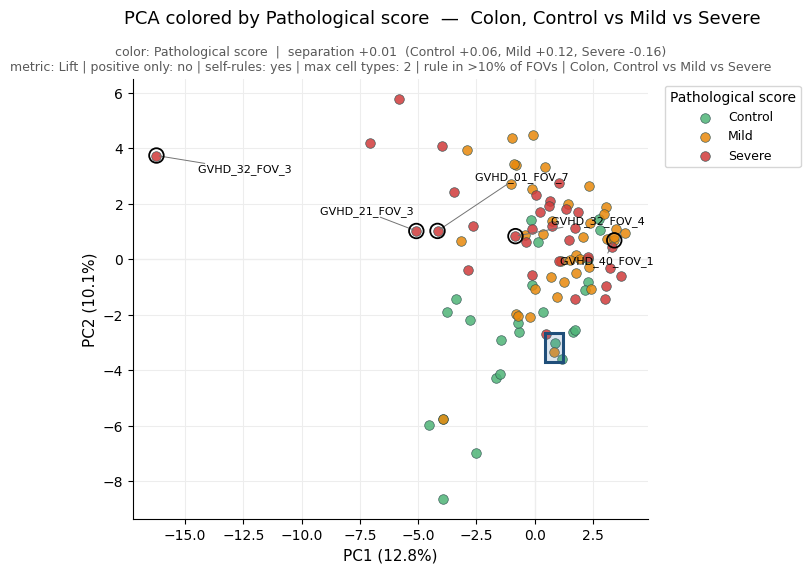

saved summary_downloads\posneg_cm_severe_colon_pair_fovs.pdf


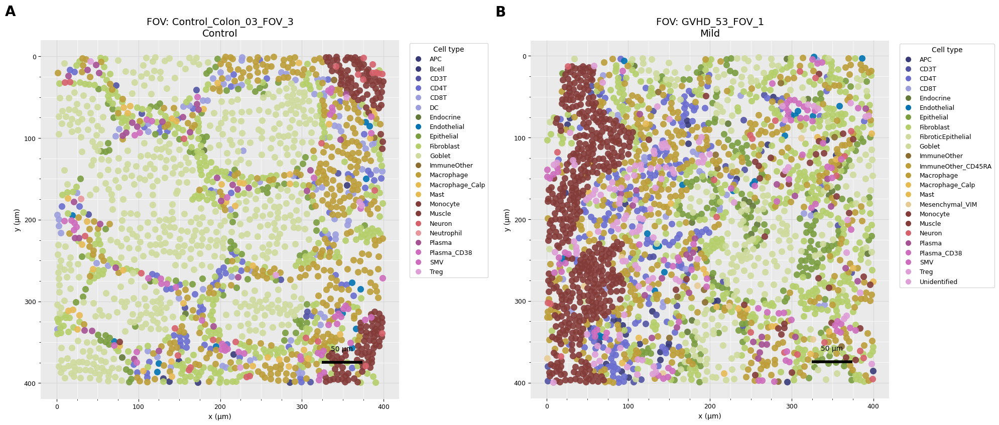

In [13]:
control_mild_severe_colon = rs.run(data,
                               stages=['Control', 'Mild', 'Severe'], organs=['Colon'],
                               prefix='posneg_cm_severe_colon', diagnostics=False)

rs.pair(data, control_mild_severe_colon, save=True);          # where the FOVs fall, and the closest pair


# 6. The figures the write-up summarises with

Every question below spans all the scopes at once, so each is one figure rather than a
table. Everything here re-fits the PCAs; nothing is read off the sections above.


In [14]:
import pandas as pd
import rule_space_vis as rsv

# Every scope, and what each is being asked to tell apart.
SCOPES = {
    'by organ':        dict(prefix='sum_all'),
    'colon, C vs S':   dict(stages=['Control', 'Severe'], organs=['Colon'],    prefix='sum_cs_colon'),
    'duodenum, C vs S':dict(stages=['Control', 'Severe'], organs=['Duodenum'], prefix='sum_cs_duo'),
    'colon, M vs S':   dict(stages=['Mild', 'Severe'],    organs=['Colon'],    prefix='sum_ms_colon'),
    'duodenum, M vs S':dict(stages=['Mild', 'Severe'],    organs=['Duodenum'], prefix='sum_ms_duo'),
    'colon, all stages':    dict(organs=['Colon'],    prefix='sum_colon'),
    'duodenum, all stages': dict(organs=['Duodenum'], prefix='sum_duo'),
}
ORGAN_OF = {name: ('Colon' if 'colon' in name else 'Duodenum')
            for name in SCOPES if name != 'by organ'}
CONTRAST_OF = {'by organ': 'colon vs duodenum',
               'colon, C vs S': 'Control vs Severe', 'duodenum, C vs S': 'Control vs Severe',
               'colon, M vs S': 'Mild vs Severe',    'duodenum, M vs S': 'Mild vs Severe'}
LABEL_OF = {name: ('Organ' if name == 'by organ' else rs.SCORE_COL) for name in SCOPES}
SWEEP_SCOPES = list(CONTRAST_OF)          # the two-group scopes only


def fit(name, min_fov=None):
    """One scope. `min_fov` overrides how often a rule must fire, for this fit only."""
    return rs.run(data, diagnostics=False, min_fov=min_fov, **SCOPES[name])


def separation_of(name, min_fov=None):
    return rs.separation(fit(name, min_fov), LABEL_OF[name])


### 6a. How thin each picture is

The first two components against everything the scope holds, so the reader knows how much
of the cloud any flat plot is showing.


both organs, all stages: 262 FOVs x 60 columns  |  PC1 12.3%  PC2 7.1%
Colon, Control vs Severe: 57 FOVs x 78 columns  |  PC1 12.6%  PC2 12.0%
Duodenum, Control vs Severe: 65 FOVs x 51 columns  |  PC1 19.3%  PC2 10.6%
Colon, Mild vs Severe: 71 FOVs x 45 columns  |  PC1 18.9%  PC2 11.6%
Duodenum, Mild vs Severe: 136 FOVs x 70 columns  |  PC1 14.4%  PC2 7.1%
Colon, all stages: 96 FOVs x 66 columns  |  PC1 12.8%  PC2 10.1%
Duodenum, all stages: 167 FOVs x 70 columns  |  PC1 12.9%  PC2 7.0%
saved summary_downloads\sum_variance.pdf


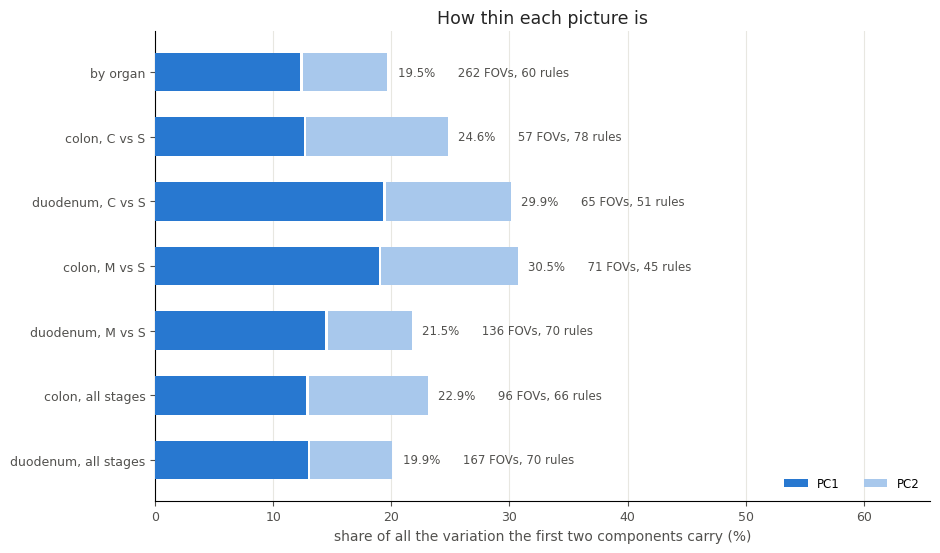

In [15]:
variance = {}
for name in SCOPES:
    scope = fit(name)
    variance[name] = {'PC1': scope.variance[0], 'PC2': scope.variance[1],
                      'FOVs': scope.matrix.shape[0], 'rules': scope.matrix.shape[1]}

rsv.plot_variance_bars(pd.DataFrame(variance).T, save=rs.figure_name('sum_variance'))


### 6b. The rules against counting the cells

The test the whole investigation turns on: if cell composition places the FOVs just as
well, the rules are adding nothing.


both organs, all stages: 262 FOVs x 60 columns  |  PC1 12.3%  PC2 7.1%
both organs, all stages, cell counts: 262 FOVs x 32 columns  |  PC1 41.3%  PC2 20.1%
Colon, Control vs Severe: 57 FOVs x 78 columns  |  PC1 12.6%  PC2 12.0%
Colon, Control vs Severe, cell counts: 57 FOVs x 32 columns  |  PC1 41.3%  PC2 30.7%
Duodenum, Control vs Severe: 65 FOVs x 51 columns  |  PC1 19.3%  PC2 10.6%
Duodenum, Control vs Severe, cell counts: 65 FOVs x 32 columns  |  PC1 57.8%  PC2 15.3%
Colon, Mild vs Severe: 71 FOVs x 45 columns  |  PC1 18.9%  PC2 11.6%
Colon, Mild vs Severe, cell counts: 71 FOVs x 32 columns  |  PC1 41.5%  PC2 23.4%
Duodenum, Mild vs Severe: 136 FOVs x 70 columns  |  PC1 14.4%  PC2 7.1%
Duodenum, Mild vs Severe, cell counts: 136 FOVs x 32 columns  |  PC1 53.8%  PC2 21.7%
Colon, all stages: 96 FOVs x 66 columns  |  PC1 12.8%  PC2 10.1%
Colon, all stages, cell counts: 96 FOVs x 32 columns  |  PC1 38.3%  PC2 25.4%
Duodenum, all stages: 167 FOVs x 70 columns  |  PC1 12.9%  PC2 7.0%
Duod

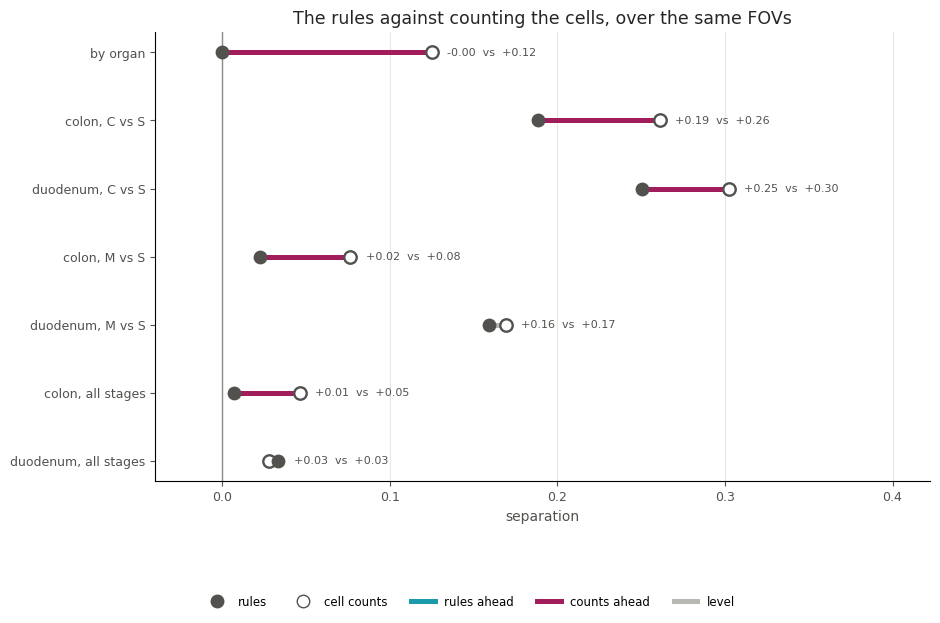

In [16]:
pairs = {}
for name in SCOPES:
    scope = fit(name)
    pairs[name] = {'rules': rs.separation(scope, LABEL_OF[name]),
                   'counts': rs.separation(rs.composition_pca(data, scope), LABEL_OF[name])}

rsv.plot_rules_against_counts(pd.DataFrame(pairs).T,
                              save=rs.figure_name('sum_rules_vs_counts'))


### 6c. What the avoidance rules are worth

Each scope with attraction rules alone, then with both signs. The slope is the answer.


both organs, all stages: 256 FOVs x 28 columns  |  PC1 15.1%  PC2 9.7%
both organs, all stages: 262 FOVs x 60 columns  |  PC1 12.3%  PC2 7.1%
Colon, Control vs Severe: 54 FOVs x 36 columns  |  PC1 15.5%  PC2 11.3%
Colon, Control vs Severe: 57 FOVs x 78 columns  |  PC1 12.6%  PC2 12.0%
Duodenum, Control vs Severe: 63 FOVs x 18 columns  |  PC1 18.1%  PC2 13.1%
Duodenum, Control vs Severe: 65 FOVs x 51 columns  |  PC1 19.3%  PC2 10.6%
Colon, Mild vs Severe: 67 FOVs x 26 columns  |  PC1 21.9%  PC2 12.1%
Colon, Mild vs Severe: 71 FOVs x 45 columns  |  PC1 18.9%  PC2 11.6%
Duodenum, Mild vs Severe: 134 FOVs x 30 columns  |  PC1 15.0%  PC2 9.1%
Duodenum, Mild vs Severe: 136 FOVs x 70 columns  |  PC1 14.4%  PC2 7.1%
Colon, all stages: 92 FOVs x 33 columns  |  PC1 15.1%  PC2 10.9%
Colon, all stages: 96 FOVs x 66 columns  |  PC1 12.8%  PC2 10.1%
Duodenum, all stages: 164 FOVs x 28 columns  |  PC1 14.4%  PC2 9.2%
Duodenum, all stages: 167 FOVs x 70 columns  |  PC1 12.9%  PC2 7.0%
saved summary_do

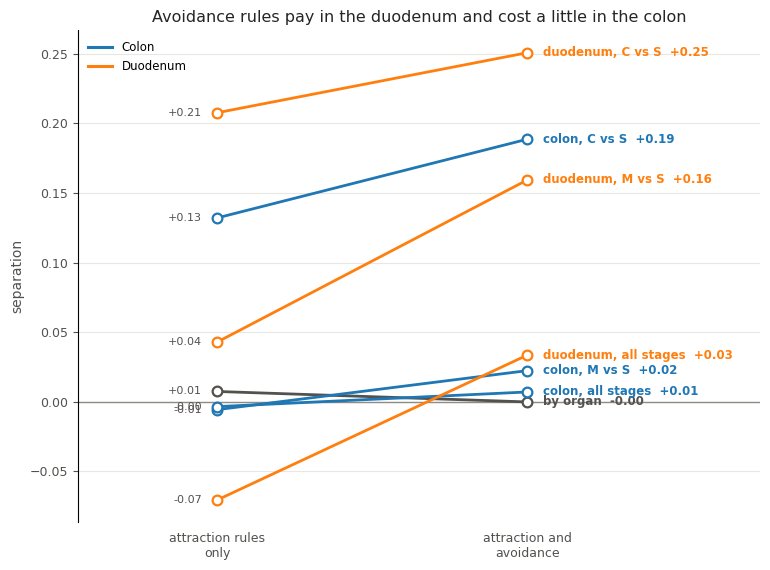

In [17]:
was_positive = rs.POSITIVE_ONLY
signs = {}
for name in SCOPES:
    rs.POSITIVE_ONLY = True
    attraction = separation_of(name)
    rs.POSITIVE_ONLY = False
    signs[name] = {'attraction': attraction, 'both': separation_of(name)}
rs.POSITIVE_ONLY = was_positive

rsv.plot_sign_slope(pd.DataFrame(signs).T, ORGAN_OF, save=rs.figure_name('sum_sign_slope'))


### 6d. How common a rule has to be

The setting every number depends on. Organ and stage want opposite answers, which is the
clearest result in the investigation.


both organs, all stages: 263 FOVs x 452 columns  |  PC1 4.1%  PC2 2.7%
Colon, Control vs Severe: 57 FOVs x 233 columns  |  PC1 9.5%  PC2 6.9%
Duodenum, Control vs Severe: 65 FOVs x 275 columns  |  PC1 6.7%  PC2 6.3%
Colon, Mild vs Severe: 71 FOVs x 236 columns  |  PC1 8.8%  PC2 6.2%
Duodenum, Mild vs Severe: 136 FOVs x 364 columns  |  PC1 4.3%  PC2 4.0%
both organs, all stages: 263 FOVs x 175 columns  |  PC1 5.6%  PC2 4.0%
Colon, Control vs Severe: 57 FOVs x 152 columns  |  PC1 9.3%  PC2 8.4%
Duodenum, Control vs Severe: 65 FOVs x 166 columns  |  PC1 9.0%  PC2 6.2%
Colon, Mild vs Severe: 71 FOVs x 147 columns  |  PC1 8.1%  PC2 7.6%
Duodenum, Mild vs Severe: 136 FOVs x 205 columns  |  PC1 6.3%  PC2 4.1%
both organs, all stages: 263 FOVs x 104 columns  |  PC1 8.4%  PC2 5.4%
Colon, Control vs Severe: 57 FOVs x 124 columns  |  PC1 10.3%  PC2 9.5%
Duodenum, Control vs Severe: 65 FOVs x 90 columns  |  PC1 13.3%  PC2 8.4%
Colon, Mild vs Severe: 71 FOVs x 90 columns  |  PC1 11.9%  PC2 9.0%
Duo

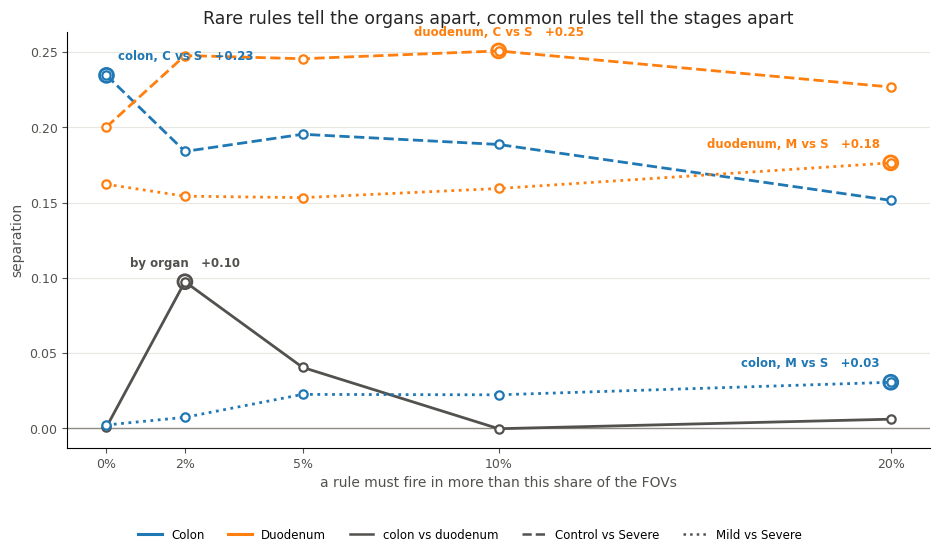

In [18]:
THRESHOLDS = [0.0, 0.02, 0.05, 0.10, 0.20]

sweep = {threshold: {name: separation_of(name, threshold) for name in SWEEP_SCOPES}
         for threshold in THRESHOLDS}

rsv.plot_threshold_sweep(pd.DataFrame(sweep).T, ORGAN_OF, CONTRAST_OF,
                         save=rs.figure_name('sum_threshold_sweep'))


### 6e. The same PCA before and after the threshold

The sweep as a number is one thing; this is what it did to the picture. Both panels are
the same FOVs and the same colours - only the rule set differs, so the axes are each
panel's own and only the grouping compares.


Colon, Control vs Severe: 57 FOVs x 152 columns  |  PC1 9.3%  PC2 8.4%
Colon, Control vs Severe: 57 FOVs x 78 columns  |  PC1 12.6%  PC2 12.0%
saved summary_downloads\sum_cs_colon_before_after.pdf


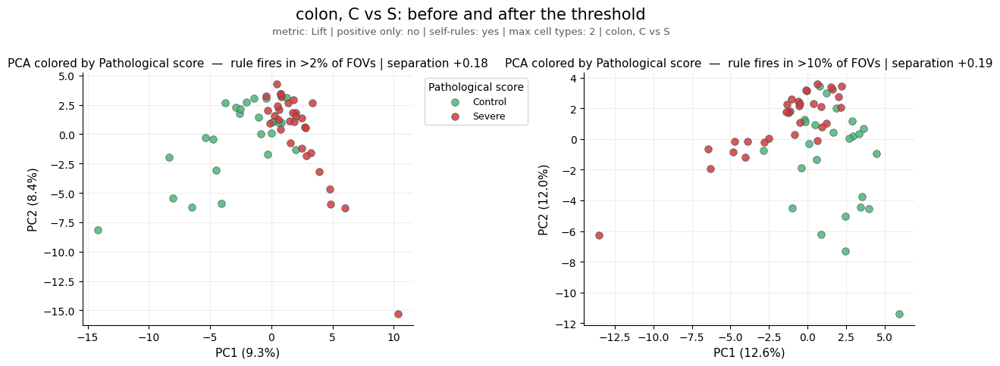

Duodenum, Control vs Severe: 65 FOVs x 166 columns  |  PC1 9.0%  PC2 6.2%
Duodenum, Control vs Severe: 65 FOVs x 51 columns  |  PC1 19.3%  PC2 10.6%
saved summary_downloads\sum_cs_duo_before_after.pdf


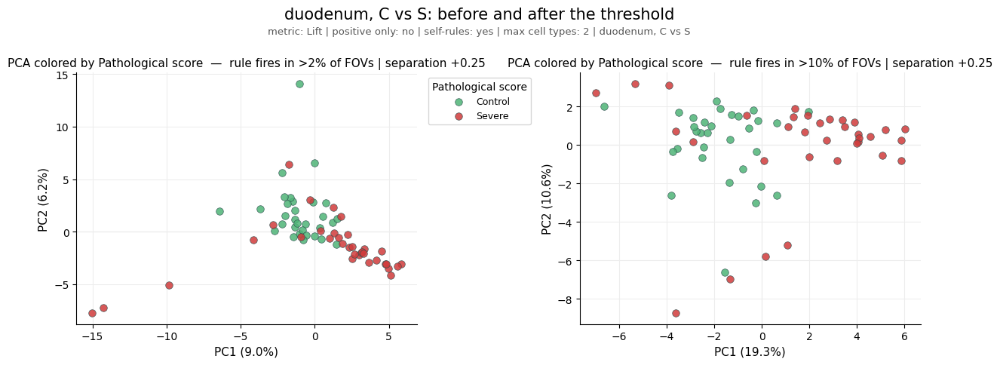

In [19]:
for name in ('colon, C vs S', 'duodenum, C vs S'):
    versions = []
    for threshold in (0.02, 0.10):
        scope = fit(name, threshold)
        scope.built_from = f'rule fires in >{threshold:.0%} of FOVs'
        versions.append(scope)

    # The threshold is the thing being compared, so it is named per panel and left out
    # of the shared line.
    shared = (f"metric: {rs.METRIC} | "
              f"positive only: {'yes' if rs.POSITIVE_ONLY else 'no'} | "
              f"self-rules: {'no' if rs.NO_SELF else 'yes'} | "
              f"max cell types: {rs.RULE_MAX_ITEMS} | {name}")
    rs.panel([versions], title=f'{name}: before and after the threshold',
             subtitle=shared,
             save=rs.figure_name(f"{SCOPES[name]['prefix']}_before_after"))
